# 03 · Model

The question here: **how many units would each commodity have sold in a given week without the promotion?**
That number is the baseline. Everything above it is incremental volume the promo actually created.

```
incremental units = actual units − baseline units
```

We never observe the "no promo" version of a promo week, so a model has to estimate it.

**Approach**

1. Train one LightGBM model on all commodities to predict weekly units from normal demand drivers
   (commodity, trend, seasonality) plus promo drivers (discount depth, display, mailer).
2. Check it on weeks it hasn't seen, and compare against a simple benchmark.
3. Re-predict every week with the promo drivers switched down to their normal level. That prediction is the baseline.

The same model is reused in notebook 04 to simulate different discount levels.

In [15]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

cw = pd.read_parquet(PROCESSED / "commodity_week.parquet")
print(f"{cw['commodity_desc'].nunique()} commodities, weeks {cw['week_no'].min()}–{cw['week_no'].max()}, {len(cw):,} rows")

184 commodities, weeks 17–101, 16,119 rows


## First, the fluid milk question

In notebook 02 fluid milk's discount fell into three separate clusters. If that's a pricing change over time
rather than week-to-week promotions, the model needs to know, otherwise it will credit the discount for
something that's really a shift in the regular price.

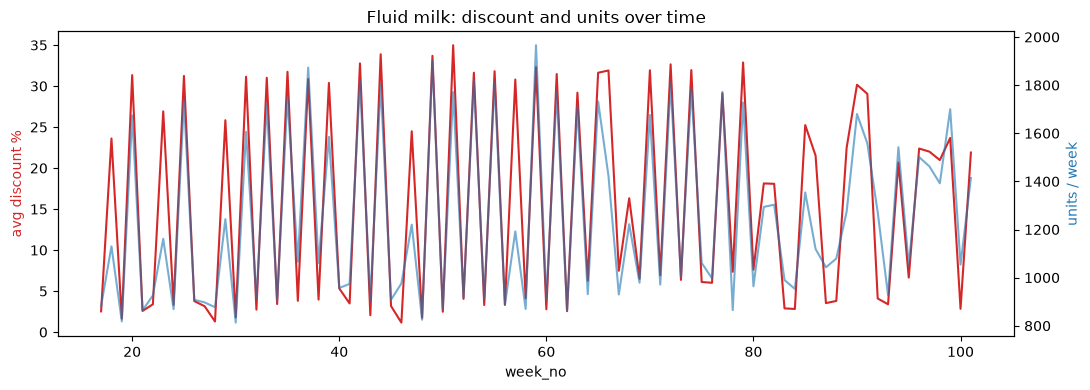

In [16]:
milk = cw.loc[cw["commodity_desc"] == "FLUID MILK PRODUCTS"].sort_values("week_no")

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(milk["week_no"], milk["avg_discount_pct"], color="tab:red", label="avg discount %")
ax1.set_ylabel("avg discount %", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(milk["week_no"], milk["units"], color="tab:blue", alpha=0.6, label="units")
ax2.set_ylabel("units / week", color="tab:blue")
ax1.set_xlabel("week_no")
ax1.set_title("Fluid milk: discount and units over time")
plt.tight_layout()
plt.savefig(FIGURES / "03_milk_discount_over_time.png", dpi=150)
plt.show()

The discount isn't a policy change. It alternates almost every other week (about 30% off, then about 3%), which is classic hi-lo pricing, and units rise and fall with it. The three clusters in notebook 02 come from this alternation.

Including list price and the trend in the model helps it separate a permanent price change from a temporary promo.

## Features

In [17]:
df = cw.copy()

# seasonality: we only have ~1.6 years, so week-of-year is seen at most twice
df["week_of_year"] = (df["week_no"] - 1) % 52 + 1

# list price relative to the commodity's own average (captures regular price changes, not promos)
df["rel_list_price"] = df["avg_list_price"] / df.groupby("commodity_desc")["avg_list_price"].transform("mean")

df["commodity"] = df["commodity_desc"].astype("category")
df["dept"] = df["department"].astype("category")

df["target"] = np.log1p(df["units"])

DEMAND_FEATURES = ["commodity", "dept", "week_no", "week_of_year", "rel_list_price"]
PROMO_FEATURES = ["avg_discount_pct", "share_display", "share_mailer"]
FEATURES = DEMAND_FEATURES + PROMO_FEATURES

df[FEATURES + ["units"]].describe(include="all").T[["count", "mean", "min", "max"]]

,count,mean,min,max
commodity,16119,NaN,NaN,NaN
dept,16119,NaN,NaN,NaN
week_no,"16,119.00",59.08,17.00,101.00
week_of_year,"16,119.00",29.03,1.00,52.00
rel_list_price,"16,119.00",1.00,0.08,8.83
avg_discount_pct,"16,119.00",11.47,0.00,69.76
share_display,"16,119.00",0.07,0.00,1.00
share_mailer,"16,119.00",0.10,0.00,1.00
units,"16,119.00",184.43,1.00,"2,658.00"


I deliberately leave out households and baskets per week. Those go up *because* of the promo,
so using them as inputs would let the model "explain" the promo effect away.

## Train / test split by time

Train on weeks 17–85, test on 86–101. A random split would let the model learn from the future.

In [18]:
SPLIT_WEEK = 85
train = df.loc[df["week_no"] <= SPLIT_WEEK]
test = df.loc[df["week_no"] > SPLIT_WEEK]
print(f"train: {len(train):,} rows (weeks {train['week_no'].min()}–{train['week_no'].max()})")
print(f"test:  {len(test):,} rows (weeks {test['week_no'].min()}–{test['week_no'].max()})")

train: 13,072 rows (weeks 17–85)
test:  3,047 rows (weeks 86–101)


## Model

**Monotone constraints:** I tell LightGBM that more discount, more display and more mailer can only
increase units, never decrease them. Without this, a tree model can learn odd wiggles
(e.g. 22% off sells less than 20% off) that make the what-if simulation in notebook 04 unreliable.

In [19]:
PARAMS = dict(
    objective="regression",
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=20,
    feature_fraction=0.9,
    bagging_fraction=0.8,
    bagging_freq=1,
    lambda_l2=1.0,
    verbose=-1,
    seed=42,
)

def fit(data, features, rounds=1500):
    monotone = [1 if f in PROMO_FEATURES else 0 for f in features]
    ds = lgb.Dataset(data[features], data["target"], categorical_feature=["commodity", "dept"])
    return lgb.train({**PARAMS, "monotone_constraints": monotone}, ds, num_boost_round=rounds)

def wape(actual, pred):
    return np.abs(actual - pred).sum() / actual.sum() * 100

model = fit(train, FEATURES)
test = test.assign(pred=np.expm1(model.predict(test[FEATURES])))

## How good is it?

Two comparisons:

- **Naive benchmark:** each commodity's average weekly units over the last 8 training weeks.
  If the model can't beat this, it isn't worth using.
- **Model without promo features:** shows how much the promo variables actually add.

In [20]:
naive = train.loc[train["week_no"] > SPLIT_WEEK - 8].groupby("commodity_desc")["units"].mean()
test = test.assign(naive=test["commodity_desc"].map(naive))

model_no_promo = fit(train, DEMAND_FEATURES)
test = test.assign(pred_no_promo=np.expm1(model_no_promo.predict(test[DEMAND_FEATURES])))

results = pd.Series({
    "naive (last 8 weeks avg)": wape(test["units"], test["naive"]),
    "model without promo features": wape(test["units"], test["pred_no_promo"]),
    "model with promo features": wape(test["units"], test["pred"]),
}, name="WAPE % (lower is better)")
results.to_frame()

,WAPE % (lower is better)
naive (last 8 weeks avg),22.70
model without promo features,17.08
model with promo features,15.32


In [21]:
# per-commodity error on the test weeks, to see where the model struggles
per_commodity = (
    test.groupby("commodity_desc")
        .apply(lambda d: pd.Series({
            "units": d["units"].sum(),
            "wape_model": wape(d["units"], d["pred"]),
            "wape_naive": wape(d["units"], d["naive"]),
        }), include_groups=False)
        .sort_values("units", ascending=False)
)
print(f"model beats naive on {(per_commodity['wape_model'] < per_commodity['wape_naive']).mean():.0%} of commodities")
per_commodity.head(15)

model beats naive on 67% of commodities


,units,wape_model,wape_naive
commodity_desc,,,
SOFT DRINKS,"26,198.00",8.56,14.98
FLUID MILK PRODUCTS,"21,068.00",9.88,18.02
SOUP,"18,379.00",21.78,97.87
CHEESE,"18,321.00",9.67,10.70
BAKED BREAD/BUNS/ROLLS,"17,196.00",8.48,8.33
VEGETABLES - SHELF STABLE,"16,017.00",8.90,14.11
BAG SNACKS,"14,279.00",7.98,9.64
FRZN MEAT/MEAT DINNERS,"13,887.00",11.43,15.56
YOGURT,"12,525.00",14.09,17.85


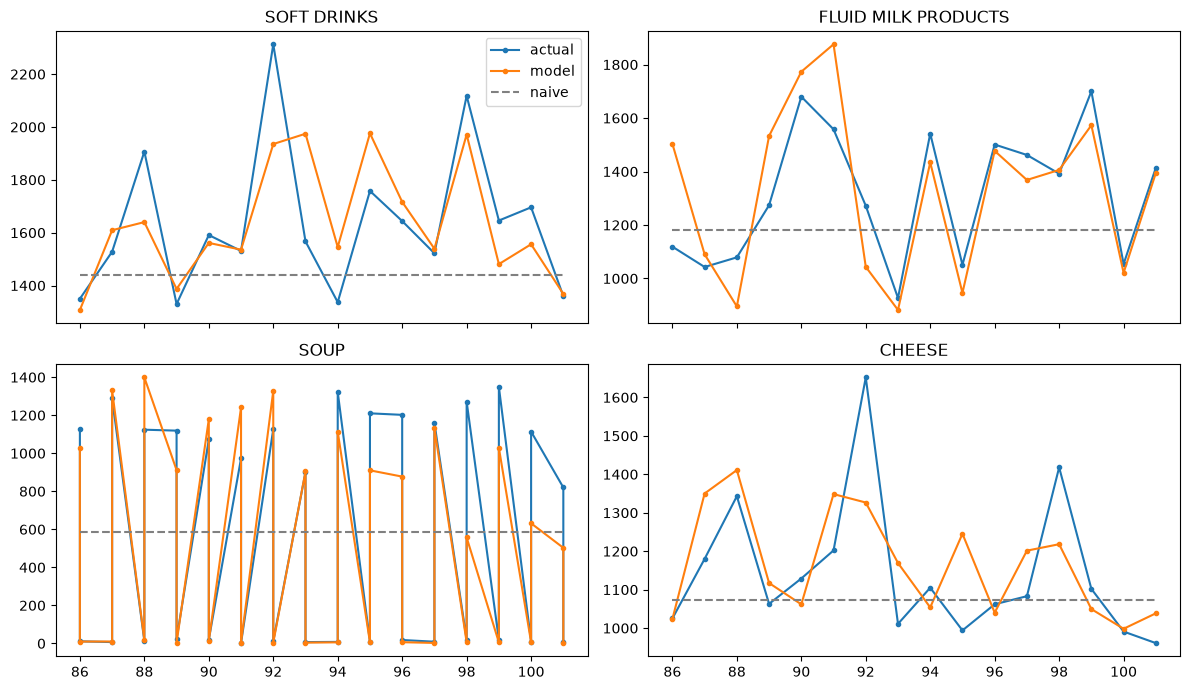

In [22]:
# actual vs predicted on the test weeks for the four biggest commodities
top4 = per_commodity.head(4).index

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, name in zip(axes.flat, top4):
    d = test.loc[test["commodity_desc"] == name].sort_values("week_no")
    ax.plot(d["week_no"], d["units"], label="actual", marker="o", ms=3)
    ax.plot(d["week_no"], d["pred"], label="model", marker="o", ms=3)
    ax.plot(d["week_no"], d["naive"], label="naive", ls="--", color="grey")
    ax.set_title(name)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig(FIGURES / "03_test_actual_vs_pred.png", dpi=150)
plt.show()

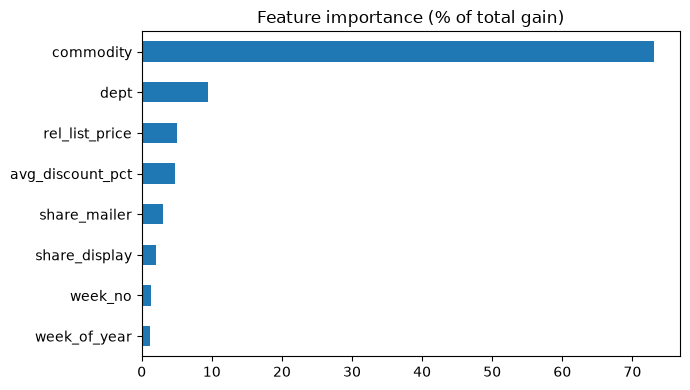

In [23]:
importance = pd.Series(
    model.feature_importance(importance_type="gain"), index=FEATURES
).sort_values()
(importance / importance.sum() * 100).plot.barh(figsize=(7, 4), title="Feature importance (% of total gain)")
plt.tight_layout()
plt.show()

## Does the discount response look sensible?

Hold everything else at a typical week and vary only the discount. The curve should rise and then flatten.
This is the same mechanic notebook 04 uses for the simulator.

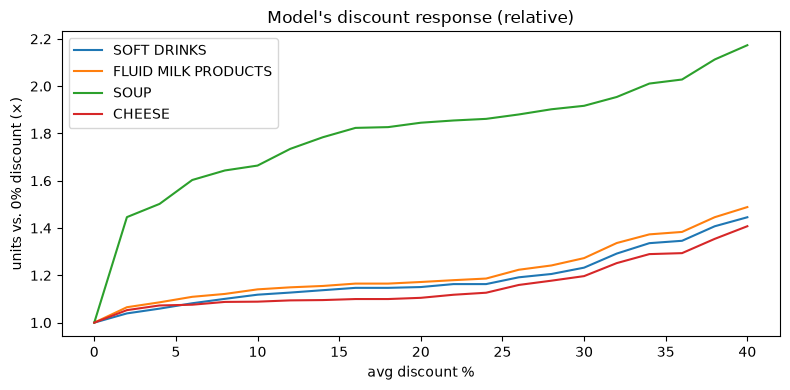

In [24]:
def response_curve(m, data, commodity, discounts):
    row = data.loc[data["commodity_desc"] == commodity, FEATURES].copy()
    typical = row.iloc[[len(row) // 2]].copy()
    typical[["share_display", "share_mailer"]] = 0
    grid = pd.concat([typical] * len(discounts), ignore_index=True)
    grid["avg_discount_pct"] = discounts
    return np.expm1(m.predict(grid))

discounts = np.arange(0, 41, 2)
fig, ax = plt.subplots(figsize=(8, 4))
for name in top4:
    units = response_curve(model, df, name, discounts)
    ax.plot(discounts, units / units[0], label=name)
ax.set_xlabel("avg discount %")
ax.set_ylabel("units vs. 0% discount (×)")
ax.set_title("Model's discount response (relative)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "03_discount_response.png", dpi=150)
plt.show()

## Baseline and incremental volume

Refit on all weeks, then predict each week twice:

- with the promo conditions that actually happened
- with promo conditions set to **normal**

**What counts as "normal"?** This store almost never sells at 0% off (soft drinks rarely go below ~5%),
and some commodities are almost always on display or in the mailer. Asking the model to predict
"0% off, no display, no mailer" would mean guessing outside the data and would overstate the promo effect.

So the baseline uses each commodity's own **low-promo week**: the 10th percentile of its discount,
display share and mailer share. If a week was already below that level, it stays as it was (no lift).

Baseline units are scaled to actual units so that the model's error doesn't show up as fake incremental volume:

```
baseline = actual × (predicted at normal conditions / predicted at actual conditions)
```

In [25]:
final_model = fit(df, FEATURES)

# each commodity's "low-promo week": 10th percentile of each promo variable
normal_levels = df.groupby("commodity_desc")[PROMO_FEATURES].quantile(0.10)
normal_discount = normal_levels["avg_discount_pct"]

baseline_X = df[FEATURES].copy()
for col in PROMO_FEATURES:
    baseline_X[col] = np.minimum(df[col], df["commodity_desc"].map(normal_levels[col]))

normal_levels.sort_values("share_display", ascending=False).head(10)

df["pred_actual"] = np.expm1(final_model.predict(df[FEATURES]))
df["pred_baseline"] = np.expm1(final_model.predict(baseline_X))
df["lift"] = (df["pred_actual"] / df["pred_baseline"]).clip(lower=1)

df["baseline_units"] = df["units"] / df["lift"]
df["incremental_units"] = df["units"] - df["baseline_units"]
df["normal_discount_pct"] = df["commodity_desc"].map(normal_discount)

total = df[["units", "baseline_units", "incremental_units"]].sum()
print(f"incremental share of all units: {total['incremental_units'] / total['units']:.1%}")

incremental share of all units: 17.6%


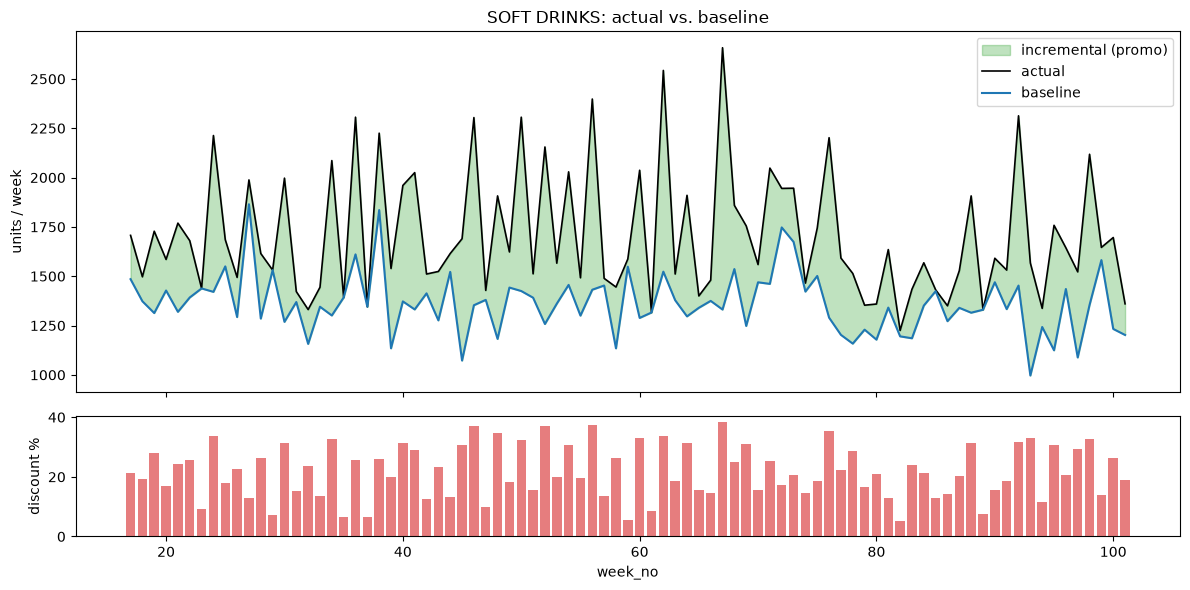

In [26]:
name = "SOFT DRINKS"
d = df.loc[df["commodity_desc"] == name].sort_values("week_no")

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].fill_between(d["week_no"], d["baseline_units"], d["units"], color="tab:green", alpha=0.3, label="incremental (promo)")
ax[0].plot(d["week_no"], d["units"], color="black", lw=1.2, label="actual")
ax[0].plot(d["week_no"], d["baseline_units"], color="tab:blue", lw=1.5, label="baseline")
ax[0].set_ylabel("units / week")
ax[0].set_title(f"{name}: actual vs. baseline")
ax[0].legend()
ax[1].bar(d["week_no"], d["avg_discount_pct"], color="tab:red", alpha=0.6)
ax[1].set_ylabel("discount %")
ax[1].set_xlabel("week_no")
plt.tight_layout()
plt.savefig(FIGURES / "03_soft_drinks_baseline.png", dpi=150)
plt.show()

## Which commodities depend most on promotions?

In [27]:
by_commodity = (
    df.groupby(["department", "commodity_desc"])
      .agg(units=("units", "sum"),
           incremental_units=("incremental_units", "sum"),
           sales_value=("sales_value", "sum"),
           avg_discount_pct=("avg_discount_pct", "mean"),
           normal_discount_pct=("normal_discount_pct", "first"))
      .assign(incremental_share=lambda d: d["incremental_units"] / d["units"] * 100)
      .reset_index()
)

big = by_commodity.loc[by_commodity["sales_value"] >= by_commodity["sales_value"].quantile(0.5)]
print("Most promo-dependent (top half by sales):")
display(big.nlargest(10, "incremental_share"))
print("Least promo-dependent (top half by sales):")
display(big.nsmallest(10, "incremental_share"))

Most promo-dependent (top half by sales):


,department,commodity_desc,units,incremental_units,sales_value,avg_discount_pct,normal_discount_pct,incremental_share
202,SEAFOOD-PCKGD,SEAFOOD - FROZEN,9073,"7,131.74","46,442.18",26.15,7.93,78.60
194,PRODUCE,TROPICAL FRUIT,36281,"25,534.73","37,001.13",6.25,0.00,70.38
123,GROCERY,SOUP,79280,"48,903.23","80,734.13",11.39,0.00,61.68
172,PRODUCE,BERRIES,12561,"6,030.62","30,518.81",11.61,0.00,48.01
177,PRODUCE,GRAPES,10087,"4,497.82","31,347.18",12.88,0.00,44.59
175,PRODUCE,CITRUS,24103,"10,744.07","22,763.83",4.32,0.00,44.58
139,MEAT,TURKEY,3606,"1,545.53","20,453.07",15.60,1.51,42.86
116,GROCERY,REFRGRATD DOUGH PRODUCTS,23364,"9,318.82","40,318.06",16.02,2.43,39.89
147,MEAT-PCKGD,MEAT - MISC,10239,"3,578.38","59,259.22",22.18,4.92,34.95
171,PRODUCE,APPLES,15293,"5,317.93","33,657.90",8.44,0.00,34.77


Least promo-dependent (top half by sales):


,department,commodity_desc,units,incremental_units,sales_value,avg_discount_pct,normal_discount_pct,incremental_share
20,DRUG GM,CIGARETTES,15279,101.02,"87,543.77",0.01,0.00,0.66
6,DELI,DELI MEATS,23804,168.78,"97,060.88",7.59,4.47,0.71
35,DRUG GM,MAGAZINE,9051,128.14,"30,153.05",0.00,0.00,1.42
49,GROCERY,BAG SNACKS,73224,"1,148.53","135,182.28",11.65,7.79,1.57
24,DRUG GM,DIAPERS & DISPOSABLES,4805,116.07,"54,394.17",5.59,2.35,2.42
95,GROCERY,HISPANIC,29065,866.06,"43,841.87",8.45,5.18,2.98
11,DRUG GM,BABY FOODS,28395,868.11,"22,064.96",3.73,0.61,3.06
50,GROCERY,BAKED BREAD/BUNS/ROLLS,90905,"4,025.73","133,259.23",20.29,17.09,4.43
141,MEAT-PCKGD,BREAKFAST SAUSAGE/SANDWICHES,15815,725.55,"42,369.61",22.53,18.09,4.59
182,PRODUCE,ONIONS,17225,824.11,"21,818.48",2.98,0.01,4.78


## Save

In [28]:
out_cols = ["department", "commodity_desc", "week_no", "units", "sales_value", "gross_value",
            "retail_disc_amt", "avg_discount_pct", "normal_discount_pct", "share_display", "share_mailer",
            "avg_list_price", "avg_price_paid", "pred_actual", "pred_baseline", "lift",
            "baseline_units", "incremental_units"]
df[out_cols].to_parquet(PROCESSED / "baseline_week.parquet", index=False)
by_commodity.to_parquet(PROCESSED / "commodity_promo_dependence.parquet", index=False)
final_model.save_model(str(PROCESSED / "units_model.txt"))
print("saved baseline_week.parquet, commodity_promo_dependence.parquet, units_model.txt")

saved baseline_week.parquet, commodity_promo_dependence.parquet, units_model.txt


## What I found

- **Accuracy on unseen weeks (86–101):** WAPE 15.3% vs. 22.7% for the naive 8-week average. Adding promo features cut error from 17.1% to 15.3%. The biggest commodities are the most accurate (soft drinks 8.6%, fluid milk 9.9%). The model beats the naive benchmark on 67% of commodities.
- **Fluid milk:** not a price policy change. The store alternates discounts almost every other week (around 30% off, then around 3%), classic hi-lo pricing, and units follow the discount closely.
- **Defining the baseline:** my first version set display and mailer to zero. Commodities like soft drinks are almost always on display or in the mailer, so that meant predicting a situation the store never runs, and incremental volume came out at 29%. Using each commodity's own low-promo week (10th percentile) brought it to **17.6% of all units**, and the soft drinks baseline now meets actual sales in low-discount weeks.
- **Least promo-dependent:** cigarettes, magazines, deli meats, bag snacks and bread show under 5% incremental volume. Bread averages 20% off but barely sells more, so most of that discount goes to customers who would have bought anyway.
- **Most promo-dependent:** mostly seasonal items (fruit, soup, turkey, frozen seafood). These are likely overstated, because the store discounts them in the season when they already sell well, and the model can't fully separate the two.
- **Limitations:** no real calendar dates, so no holiday features. Promo timing isn't random, so these are associations, not proof of cause.